# Week 6: Root-finding and optimization

[Open in Colab](https://colab.research.google.com/github/WSU-EconS431/site/blob/main/weeks/week06.ipynb) · [View on GitHub](https://github.com/WSU-EconS431/site/blob/main/weeks/week06.ipynb)

Most economic models have an equilibrium that solves an equation or a choice that maximizes an objective, and most realistic versions have no tidy formula. In Week 2 you wrote **bisection** to solve an equation by repeatedly halving a bracket, and in Week 3 you searched a **grid** for a maximum. This week you use SciPy's professional versions of both, and learn what to check afterward.

**After this week you can:**

- find where a function equals zero (an equilibrium) with `brentq` and `root_scalar`, and check the answer
- solve a system of equations with `root`
- maximize or minimize with `minimize_scalar` and `minimize`, including bounds and a budget constraint
- apply them to a tax, a monopoly, and a consumer's choice
- compute areas under curves (consumer and producer surplus) with `quad`
- recognize when a solver can fail: no sign change, local optima, a bad starting point

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, root_scalar, root, minimize_scalar, minimize
from scipy.integrate import quad

## 1. An equilibrium with a tax

Demand is $Q_d = A\,P^{-\varepsilon}$, which has constant elasticity $-\varepsilon$. Supply is $Q_s = B\,(P - t)^{\gamma}$ for a per-unit tax $t$ on sellers: sellers keep $P - t$. With no tax there is a formula, $P^* = (A/B)^{1/(\varepsilon + \gamma)}$, which we use to check our answers. **With a tax, there is no formula**, so we solve $Q_d(P) = Q_s(P)$ numerically.

In [2]:
A, eps, B, gamma = 200, 1.5, 5, 0.8

def demand(p):
    return A * p ** (-eps)

def supply(p, t=0):
    """Quantity supplied when buyers pay p and sellers keep p - t."""
    return B * np.maximum(p - t, 0) ** gamma

def excess(p, t=0):
    """Excess demand. The equilibrium price is where this is zero."""
    return demand(p) - supply(p, t)

p_formula = (A / B) ** (1 / (eps + gamma))
print(f"no-tax equilibrium from the formula: P* = {p_formula:.4f}, Q* = {demand(p_formula):.3f}")

no-tax equilibrium from the formula: P* = 4.9722, Q* = 18.039


**`brentq(f, a, b)`** finds a zero of `f` between `a` and `b`. Like bisection it needs a **bracket**: `f(a)` and `f(b)` must have opposite signs. Excess demand is positive at a low price and negative at a high price, so any wide bracket works.

In [3]:
print(excess(0.5), excess(100))           # positive, then negative: the bracket is valid
p_star = brentq(excess, 0.5, 100)
print(f"brentq: P* = {p_star:.6f}")

562.8136790617455 -198.85358527674867
brentq: P* = 4.972191


**Always check the answer.** Here we can compare with the formula, and in general you check that the function really is close to zero at the answer (the **residual**):

In [4]:
print("residual:", excess(p_star))
assert np.isclose(p_star, p_formula)

residual: 0.0


`root_scalar` is the same solver with a report on what happened. Compare the work with your Week 2 bisection (which halves the bracket every time):

In [5]:
def bisect_count(f, lo, hi, tol=1e-12):
    n = 0
    while hi - lo > tol:
        mid = (lo + hi) / 2
        if f(lo) * f(mid) <= 0:
            hi = mid
        else:
            lo = mid
        n += 1
    return (lo + hi) / 2, n

res = root_scalar(excess, bracket=[0.5, 100], method="brentq")
print(f"brentq:   root {res.root:.8f}, {res.iterations} iterations, converged: {res.converged}")
p_bis, n_bis = bisect_count(excess, 0.5, 100)
print(f"bisection: root {p_bis:.8f}, {n_bis} iterations")

brentq:   root 4.97219122, 11 iterations, converged: True
bisection: root 4.97219122, 47 iterations


Brent's method combines bisection's safety with faster steps when the function is smooth, so it needs far fewer evaluations. Both need a sign change; without one they stop with an error rather than a wrong answer:

In [6]:
#| error: true
brentq(excess, 10, 100)       # excess demand is negative at both ends: no bracket

ValueError: f(a) and f(b) must have different signs

## 2. Passing parameters with `args`

The solver calls `f(x)` with one number, but our `excess` also needs the tax. Pass extra arguments with `args=(...)`, or wrap the function in a `lambda`. Now solve for a tax of 2 per unit. The lowest price sellers will accept is $t$, so the bracket starts just above $t$:

In [7]:
t = 2
res = root_scalar(excess, args=(t,), bracket=[t + 1e-6, 200], method="brentq")
p_c = res.root              # price buyers pay
p_s = p_c - t               # price sellers keep
q_t = demand(p_c)
print(f"buyers pay {p_c:.3f}, sellers keep {p_s:.3f}, quantity {q_t:.3f} (was {demand(p_formula):.3f})")
print(f"consumers bear {(p_c - p_formula) / t:.0%} of the tax, sellers {(p_formula - p_s) / t:.0%}")
print("residual:", excess(p_c, t))

buyers pay 5.766, sellers keep 3.766, quantity 14.444 (was 18.039)
consumers bear 40% of the tax, sellers 60%
residual: 0.0


The tax raises the price buyers pay by less than the tax and lowers the price sellers keep, so the burden is **shared**; with these elasticities consumers bear about 40%. (Week 10 explains why the split depends on the elasticities.) Putting the solve in a function lets us study many tax rates:

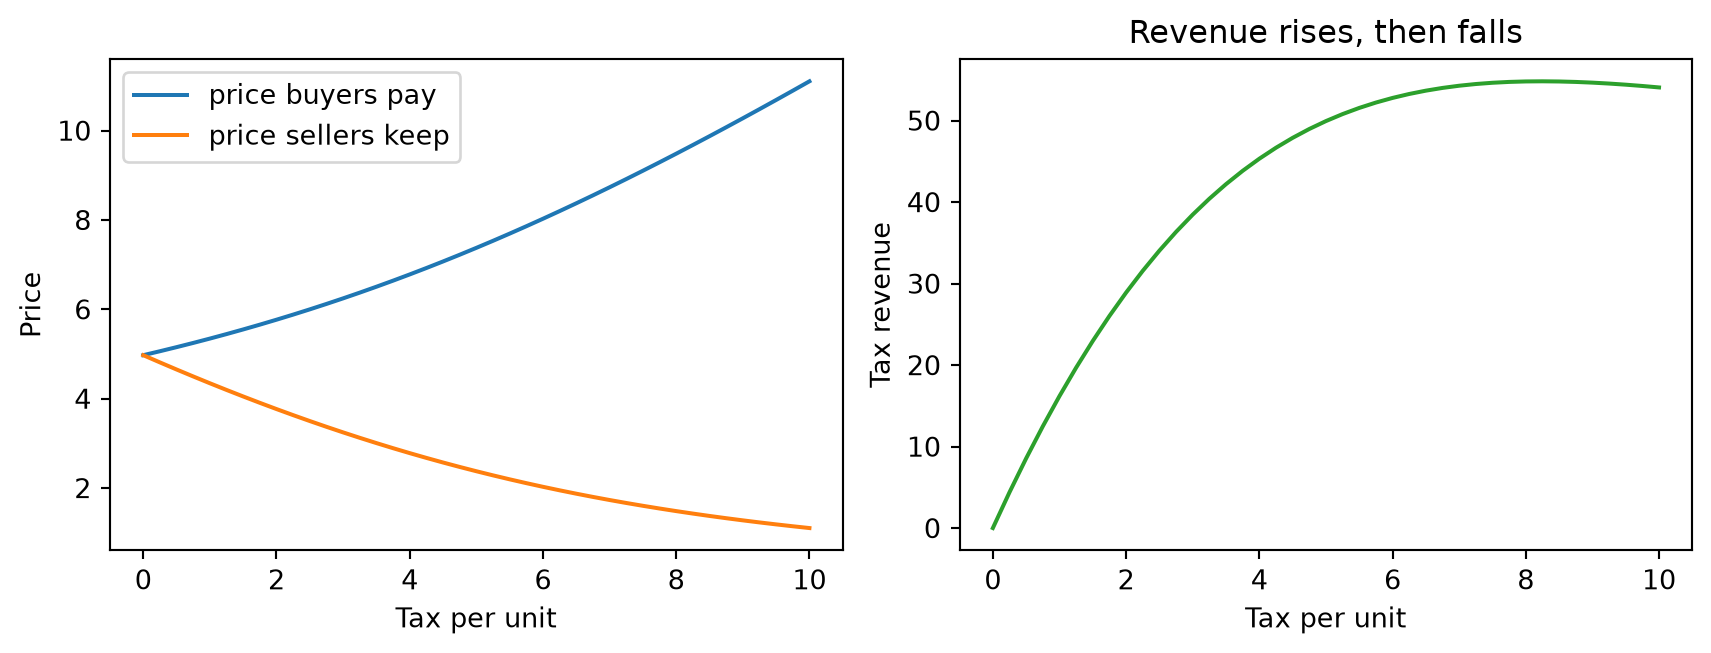

In [8]:
def solve_market(t):
    """Equilibrium price buyers pay when the tax is t."""
    return root_scalar(excess, args=(t,), bracket=[t + 1e-6, 200], method="brentq").root

taxes = np.linspace(0, 10, 41)
p_buy = np.array([solve_market(t) for t in taxes])
q_eq = demand(p_buy)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
ax1.plot(taxes, p_buy, label="price buyers pay")
ax1.plot(taxes, p_buy - taxes, label="price sellers keep")
ax1.set_xlabel("Tax per unit")
ax1.set_ylabel("Price")
ax1.legend()
ax2.plot(taxes, taxes * q_eq, color="tab:green")
ax2.set_xlabel("Tax per unit")
ax2.set_ylabel("Tax revenue")
ax2.set_title("Revenue rises, then falls")
fig.tight_layout()
plt.show()

## 3. Systems of equations: `root`

When two markets interact, you solve for two prices at once. Let coffee (price $p_1$) and tea ($p_2$) be substitutes: demand for each falls with its own price and rises with the other's. The function returns the **vector** of excess demands, and `root` finds the vector of prices where both are zero from a starting guess `x0`.

In [9]:
def excess_two(p):
    p1, p2 = p
    ed1 = 100 * p1 ** -1.2 * p2 ** 0.3 - 4 * p1       # demand minus supply, market 1
    ed2 = 80 * p2 ** -1.0 * p1 ** 0.2 - 6 * p2        # demand minus supply, market 2
    return [ed1, ed2]

sol = root(excess_two, x0=[5.0, 5.0])
print("success:", sol.success, " prices:", sol.x.round(4))
print("residuals:", np.array(excess_two(sol.x)).round(10))

success: True  prices: [5.272  4.3119]
residuals: [-2.e-10 -0.e+00]


A system has no bracket, so `root` needs a **starting guess**. Try other starting guesses; if different ones give different answers, or `success` is `False`, investigate before trusting any of them.

## 4. Optimization: `minimize_scalar`

SciPy only minimizes, so to maximize profit you minimize **minus** profit. A monopolist faces inverse demand $P = a - bq$ and cost $C(q) = F + cq + dq^2/2$. Profit is $\pi(q) = (a - bq)q - C(q)$ and calculus gives $q^* = (a - c)/(2b + d)$, which we use to check the solver.

In [10]:
a, b, c, d, F = 100, 2, 10, 1, 50

def profit(q):
    return (a - b * q) * q - (F + c * q + d * q ** 2 / 2)

res = minimize_scalar(lambda q: -profit(q), bounds=(0, a / b), method="bounded")
print(f"solver: q = {res.x:.4f}, profit = {-res.fun:.3f}, success: {res.success}")
print(f"calculus: q = {(a - c) / (2 * b + d):.4f}")

solver: q = 18.0000, profit = 760.000, success: True
calculus: q = 18.0000


`bounds=(0, a/b)` keeps the search where the model makes sense (quantity between 0 and the choke quantity), and `method="bounded"` is the scalar method that respects them. Because the optimizer works on whatever function you give it, the same code solves the problem when cost is complicated and calculus is messy.

Optimizers can be nested. A government that wants to **maximize tax revenue** chooses $t$ to maximize $t \cdot Q(t)$, where $Q(t)$ comes from solving the market (Section 2). The inner solve runs inside the objective:

In [11]:
def revenue(t):
    return t * demand(solve_market(t))

res = minimize_scalar(lambda t: -revenue(t), bounds=(0, 10), method="bounded")
print(f"revenue-maximizing tax: {res.x:.3f}, revenue {-res.fun:.2f}, success: {res.success}")

revenue-maximizing tax: 8.229, revenue 54.81, success: True


That agrees with the right-hand figure in Section 2, where revenue peaks at a tax a little above 8 and then falls as the tax shrinks the market.

## 5. A constrained choice: `minimize`

A consumer with income $m$ buys $x$ and $y$ at prices $p_x$ and $p_y$ to maximize Cobb–Douglas utility $u = x^{\alpha} y^{1-\alpha}$ subject to the budget $p_x x + p_y y = m$. The solution has a formula, $x^* = \alpha m/p_x$ and $y^* = (1-\alpha)m/p_y$, so we can check the solver, but the code below works for any utility function.

In [12]:
alpha, px, py, m = 0.4, 2.0, 5.0, 100.0

def utility(z):
    x, y = z
    return x ** alpha * y ** (1 - alpha)

budget = {"type": "eq", "fun": lambda z: m - px * z[0] - py * z[1]}      # equals zero when the budget is spent

res = minimize(lambda z: -utility(z), x0=[10.0, 5.0], bounds=[(1e-9, None), (1e-9, None)],
               constraints=[budget], method="SLSQP")
print("success:", res.success, " x, y =", res.x.round(4), " utility =", round(-res.fun, 4))
print("formula:", alpha * m / px, (1 - alpha) * m / py)

success: True  x, y = [20. 12.]  utility = 14.7204
formula: 20.0 12.0


`x0` is a starting guess, `bounds` keeps both goods positive (the logarithm and powers misbehave at zero), and the constraint dictionary says the budget holds with equality.

## 6. Areas under curves: `quad`

Consumer surplus is the area between the demand curve and the price, from 0 to the quantity bought: $CS = \int_0^{Q}\bigl(P_d(q) - p\bigr)\,dq$, where $P_d(q) = (A/q)^{1/\varepsilon}$ is the inverse demand. `quad(f, a, b)` integrates numerically and returns the area and an error estimate. Producer surplus is the area between the price sellers keep and the supply curve $P_s(q) = (q/B)^{1/\gamma}$.

In [13]:
P_d = lambda q: (A / q) ** (1 / eps)         # inverse demand
P_s = lambda q: (q / B) ** (1 / gamma)       # inverse supply

def welfare(p_buy, p_sell, q):
    cs = quad(lambda x: P_d(x) - p_buy, 0, q)[0]
    ps = quad(lambda x: p_sell - P_s(x), 0, q)[0]
    return cs, ps

q0 = demand(p_formula)
cs0, ps0 = welfare(p_formula, p_formula, q0)
cs_formula = A ** (1 / eps) * q0 ** (1 - 1 / eps) / (1 - 1 / eps) - p_formula * q0      # integral by hand
print(f"no tax:  CS = {cs0:.2f} (by hand {cs_formula:.2f}), PS = {ps0:.2f}")

cs1, ps1 = welfare(p_c, p_s, q_t)
revenue_2 = t * q_t
dwl = (cs0 + ps0) - (cs1 + ps1 + revenue_2)
print(f"tax of {t}: CS = {cs1:.2f}, PS = {ps1:.2f}, revenue = {revenue_2:.2f}, deadweight loss = {dwl:.2f}")

no tax:  CS = 179.38 (by hand 179.38), PS = 49.83
tax of 2: CS = 166.58, PS = 30.22, revenue = 28.89, deadweight loss = 3.53


The tax transfers some surplus to the government as revenue and destroys the rest of the loss: the **deadweight loss**. You'll use this calculation again in Module 4.

## 7. When solvers fail

**Local optima.** An optimizer follows the function uphill (or downhill) from the starting guess and stops at the first peak it reaches. If the function has several peaks, different starts give different answers:

start   -4: peak at x = -3.569, f = -1.463
start   -1: peak at x = -1.498, f = 0.115
start  0.5: peak at x =  0.573, f = 1.259
start    3: peak at x =  2.644, f = 1.969


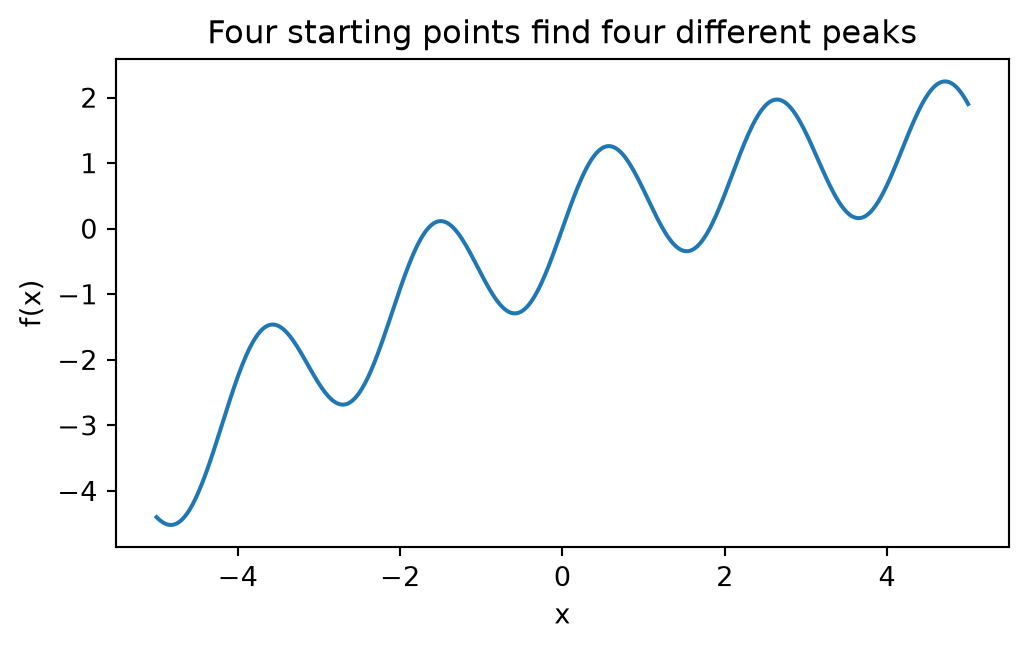

In [14]:
def f(x):
    return np.sin(3 * x) + 0.5 * x - 0.05 * x ** 2      # a function with several peaks

for x0 in [-4, -1, 0.5, 3]:
    r = minimize(lambda z: -f(z[0]), [x0])
    print(f"start {x0:>4}: peak at x = {r.x[0]:6.3f}, f = {-r.fun:.3f}")

xs = np.linspace(-5, 5, 400)
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.plot(xs, f(xs))
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title("Four starting points find four different peaks")
plt.show()

Only one of those peaks is the **global** maximum. The usual defense is to try several starting guesses (or a coarse grid search first, as in Week 3) and keep the best, and to plot the function when you can.

**A checklist after any solver call:**

1. Did it report success? (`res.success`, `res.converged`, `res.message`)
2. Is the residual (or the first-order condition) close to zero at the answer?
3. Does the answer make economic sense (positive price, quantity within bounds)?
4. Does a closed form, a grid search, or another starting guess give the same answer?
5. Is the answer at a bound? That means the bound, not the optimizer, chose it.

## 8. In-class lab

The exercises for this week are in **Lab 6**. It appears in the `lab06` folder of your repository at the start of the second class session (pull to see it), and you work on it in pairs.

## This week

- Read *Python Programming for Economics and Finance*: [12. SciPy](https://python-programming.quantecon.org/scipy.html).
- **PS06** (a market with a tax, a monopoly, a consumer's choice) is in the `ps06` folder of your repo.
- Next week: linear algebra and Markov chains.